# 05b. 다국어 임베딩 검증과 추천확률 산출

**입력**: `dataSets/starfield_embeddings.npz` (05a에서 Colab으로 만든 multilingual-e5-large 임베딩),
`dataSets/starfield_analysis.csv`, `dataSets/reviews_for_embedding.csv` (분석 대상 id)
**비교용**: `dataSets/starfield_emb_qwen3_cls.npz` (Qwen3-Embedding-0.6B)
**출력**: `dataSets/추천확률.csv`, `out/05b_언어별_AUC.png`

리뷰 텍스트(임베딩)로 추천/비추천(voted_up)을 맞히는 로지스틱 회귀를 만들고,
그 예측확률 P(추천 | 텍스트)를 **추천확률**이라는 점수로 뒤의 분석에 쓴다. 1에 가까울수록 글이 추천에 가깝다.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GroupShuffleSplit, StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, accuracy_score, recall_score, precision_score

RANDOM_STATE = 3217
os.makedirs('out', exist_ok=True)

# 한글 폰트: 폴더에 있는 폰트 파일을 쓰고, 없으면 맥 기본 폰트(AppleGothic)를 쓴다
FONT_FILE = 'helpers/fonts/NotoSansKR-Regular.ttf'
if os.path.exists(FONT_FILE):
    font_manager.fontManager.addfont(FONT_FILE)                                   # 폰트 파일 등록
    plt.rcParams['font.family'] = font_manager.FontProperties(fname=FONT_FILE).get_name()   # 파일 안의 폰트 이름을 읽어 지정
else:
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

C_POS = '#4C72B0'
C_NEG = '#C44E52'

## 1. 임베딩과 원본 데이터 병합

임베딩 파일에는 벡터(행)와 steamid가 같은 순서로 들어 있다.
원본을 분석 대상 id로 거른 뒤, steamid로 임베딩 행 번호를 붙여서 **벡터 순서와 데이터프레임 순서를 맞춘다**.
이 순서가 어긋나면 에러 없이 조용히 틀린 결과가 나오므로 행 수를 꼭 확인한다.

In [2]:
def load_embeddings(npz_path):
    """임베딩 파일을 읽어 분석 대상 데이터프레임(df)과 같은 순서의 벡터 배열(X)을 돌려준다."""
    z = np.load(npz_path)
    vectors = z['embeddings'].astype(np.float32)   # 저장은 float16, 계산은 float32
    ids = z['steamid']

    meta = pd.read_csv('dataSets/starfield_analysis.csv', low_memory=False)
    pop = pd.read_csv('dataSets/reviews_for_embedding.csv', usecols=['steamid'])

    # 임베딩 파일의 steamid → 몇 번째 행인지 표
    emb = pd.DataFrame({'steamid': ids, 'row': np.arange(len(ids))})

    df = meta.merge(pop, on='steamid', how='inner')     # 분석 대상만 남기고
    df = df.merge(emb, on='steamid', how='inner')       # 임베딩 행 번호를 붙인다
    df = df.reset_index(drop=True)
    if len(df) != len(pop):
        raise ValueError('임베딩에 없는 행이 있다 — 05a를 다시 실행')

    X = vectors[df['row'].values]      # df 순서대로 벡터를 꺼낸다
    df = df.drop(columns='row')
    print('분석 대상', len(df), '행 / 벡터', X.shape)
    return X, df


X, df = load_embeddings('dataSets/starfield_embeddings.npz')
df['len'] = df['review'].str.len()
y = df['voted_up'].astype(int).values     # 추천=1, 비추천=0
print('긍정률', round(y.mean(), 3), '/ 언어', df['language'].nunique(), '종')

분석 대상 70915 행 / 벡터 (70915, 1024)
긍정률 0.572 / 언어 29 종


## 2. 학습/평가 분할 (80 / 20)

voted_up 비율이 두 쪽에서 같도록(stratify) 나눈다.

In [3]:
idx = np.arange(len(df))
train_idx, test_idx = train_test_split(idx, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print('학습', len(train_idx), '/ 평가', len(test_idx))

# 나눈 뒤에도 언어 구성비가 비슷한지 확인 (상위 5개 언어)
top5 = df['language'].value_counts().head(5).index
for lang in top5:
    all_share = (df['language'] == lang).mean() * 100
    test_share = (df['language'].iloc[test_idx] == lang).mean() * 100
    print(f'{lang:<10} 전체 {all_share:.2f}%  평가 {test_share:.2f}%')


def fit_and_score(features, label):
    """로지스틱 회귀를 학습 데이터로 학습하고 평가 데이터의 AUC·정확도를 출력한다."""
    model = LogisticRegression(max_iter=300)
    model.fit(features[train_idx], y[train_idx])
    proba = model.predict_proba(features[test_idx])[:, 1]   # 추천일 확률
    auc = roc_auc_score(y[test_idx], proba)
    acc = accuracy_score(y[test_idx], proba >= 0.5)
    print(f'{label:<28} AUC {auc:.4f} | 정확도 {acc:.4f}')
    return model

학습 56732 / 평가 14183
english    전체 59.57%  평가 60.14%
schinese   전체 21.20%  평가 20.80%
german     전체 4.18%  평가 3.91%
french     전체 3.19%  평가 3.32%
spanish    전체 1.94%  평가 2.02%


## 3. 기준선과 모델 비교

- **리뷰 길이만** 쓴 모델을 먼저 만든다. 길이와 감성에 상관이 있어서(짧은 글은 긍정이 많다), 임베딩 모델의 성능이 내용을 읽은 것인지 길이만 본 것인지 구분하려면 이 기준선이 필요하다.
- 같은 텍스트("good", "10/10")가 학습과 평가 양쪽에 들어가면 성능이 부풀려진다. 같은 텍스트는 한쪽에만 두는 **그룹 분할** 결과도 같이 본다.

In [4]:
# 같은 텍스트 → 같은 그룹 번호
groups = pd.factorize(df['review'])[0]
n_unique = groups.max() + 1
print('고유 텍스트', n_unique, '개 / 전체', len(df), '건 (중복', len(df) - n_unique, '건)')

length_feature = np.log1p(df['len'].values).reshape(-1, 1)   # 길이 하나짜리 특성
fit_and_score(length_feature, '(1) 리뷰 길이만')
fit_and_score(X, '(2) multilingual-e5-large')

# 리더보드 상위 모델(Qwen3)과 같은 분할에서 비교 — 우리 데이터에서는 e5가 조금 더 낫다
X_qwen, df_qwen = load_embeddings('dataSets/starfield_emb_qwen3_cls.npz')
fit_and_score(X_qwen, '(2-alt) Qwen3-Embedding-0.6B')

# 그룹 분할: 같은 텍스트가 학습·평가에 갈라지지 않게 나눈다
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
g_train, g_test = next(splitter.split(idx, y, groups=groups))
model = LogisticRegression(max_iter=300)
model.fit(X[g_train], y[g_train])
proba = model.predict_proba(X[g_test])[:, 1]
print(f'{"(3) 그룹 분할(중복 격리)":<28} AUC {roc_auc_score(y[g_test], proba):.4f} | 정확도 {accuracy_score(y[g_test], proba >= 0.5):.4f}')

고유 텍스트 66209 개 / 전체 70915 건 (중복 4706 건)
(1) 리뷰 길이만                   AUC 0.5740 | 정확도 0.5803
(2) multilingual-e5-large    AUC 0.9537 | 정확도 0.8866
분석 대상 70915 행 / 벡터 (70915, 1024)
(2-alt) Qwen3-Embedding-0.6B AUC 0.9530 | 정확도 0.8837
(3) 그룹 분할(중복 격리)             AUC 0.9497 | 정확도 0.8832


## 4. 추천확률 산출 (out-of-fold)

여기서부터는 모델을 평가하는 게 아니라 **전체 리뷰에 점수를 매긴다**.
위에서 학습한 모델을 전체에 그대로 쓰면 학습에 들어간 80%는 자기가 본 데이터를 예측하는 셈이라 확률이 지나치게 확신하는 쪽으로 치우친다.

그래서 데이터를 5조각으로 나누고, 각 조각은 **나머지 4조각으로 학습한 모델**로 점수를 매긴다(out-of-fold).
중복 텍스트가 조각을 넘나들지 않도록 groups도 넘긴다.

In [5]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof_proba = cross_val_predict(LogisticRegression(max_iter=300), X, y, cv=cv, groups=groups, method='predict_proba')[:, 1]
oof_pred = (oof_proba >= 0.5).astype(int)

print(f'OOF AUC {roc_auc_score(y, oof_proba):.4f} | 정확도 {accuracy_score(y, oof_pred):.4f}  (전체 {len(df):,}건)')
print(f'비추천 재현율 {recall_score(y, oof_pred, pos_label=0):.3f} · 정밀도 {precision_score(y, oof_pred, pos_label=0):.3f}')
print(f'추천   재현율 {recall_score(y, oof_pred):.3f} · 정밀도 {precision_score(y, oof_pred):.3f}')

df['추천확률'] = oof_proba
df[['steamid', '추천확률']].to_csv('dataSets/추천확률.csv', index=False)
print('저장: dataSets/추천확률.csv')

OOF AUC 0.9541 | 정확도 0.8869  (전체 70,915건)
비추천 재현율 0.858 · 정밀도 0.876
추천   재현율 0.909 · 정밀도 0.895
저장: dataSets/추천확률.csv


### 확률 보정 확인

추천확률을 점수로 쓰려면 "예측 0.4인 리뷰들의 실제 추천 비율이 0.4 근처"여야 한다. 구간별로 확인한다.

In [6]:
bins = [0, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0]
df['구간'] = pd.cut(df['추천확률'], bins)
calib = df.groupby('구간', observed=True).agg(n=('voted_up', 'size'), 실제긍정률=('voted_up', 'mean'), 평균예측=('추천확률', 'mean'))
print(calib.round(3))

                n  실제긍정률   평균예측
구간                             
(0.0, 0.1]  15577  0.028  0.036
(0.1, 0.3]   8857  0.151  0.184
(0.3, 0.5]   5311  0.362  0.397
(0.5, 0.7]   5795  0.600  0.609
(0.7, 0.9]  10167  0.851  0.817
(0.9, 1.0]  25208  0.981  0.968


## 5. 언어별 성능 (out-of-fold 기준)

전체 AUC만 보면 다국어로 간 의미를 검증할 수 없다. 리뷰 100건 이상인 언어별로 AUC를 보고, 50자 이상만 남겨도 격차가 남는지 확인한다.

In [7]:
def perf_by_language(data, min_n=100):
    """언어별 n, 긍정률, AUC, 정확도 표. 리뷰가 min_n 미만인 언어는 뺀다."""
    rows = []
    for lang, g in data.groupby('language'):
        if len(g) < min_n:
            continue
        label = g['voted_up'].astype(int)
        if label.nunique() < 2:        # 한쪽 클래스만 있으면 AUC를 계산할 수 없다
            continue
        rows.append({
            'language': lang,
            'n': len(g),
            '긍정률': label.mean(),
            'AUC': roc_auc_score(label, g['추천확률']),
            '정확도': accuracy_score(label, g['추천확률'] >= 0.5),
            '평균길이': g['len'].mean(),
        })
    return pd.DataFrame(rows).set_index('language').sort_values('AUC', ascending=False)


lang_perf = perf_by_language(df)
print(lang_perf.round(3))

# 길이 통제: 50자 이상만 남기고 다시 계산
long_perf = perf_by_language(df[df['len'] >= 50])
compare = pd.DataFrame({'전체 AUC': lang_perf['AUC'], '50자+ AUC': long_perf['AUC']}).dropna()
compare['변화'] = compare['50자+ AUC'] - compare['전체 AUC']
print()
print('[길이 통제 전후]')
print(compare.round(3))

               n    긍정률    AUC    정확도     평균길이
language                                      
hungarian    102  0.814  0.980  0.951  386.549
german      2964  0.651  0.973  0.919  592.473
french      2259  0.596  0.969  0.911  626.255
english    42244  0.564  0.968  0.910  532.034
dutch        157  0.777  0.968  0.943  233.822
czech        261  0.655  0.963  0.908  516.115
latam        242  0.777  0.961  0.921  522.207
swedish      123  0.675  0.961  0.894  215.626
italian      533  0.707  0.957  0.906  573.848
spanish     1376  0.730  0.956  0.914  501.124
polish       737  0.562  0.953  0.877  398.674
ukrainian    201  0.612  0.952  0.896  594.836
brazilian   1030  0.767  0.944  0.911  566.478
japanese     330  0.624  0.935  0.882  455.042
russian     1097  0.572  0.907  0.823  675.976
tchinese     345  0.629  0.903  0.835  166.612
schinese   15031  0.527  0.899  0.820  130.721
turkish      878  0.647  0.883  0.825  396.989
koreana      610  0.352  0.855  0.749  190.359

[길이 통제 전후]
 

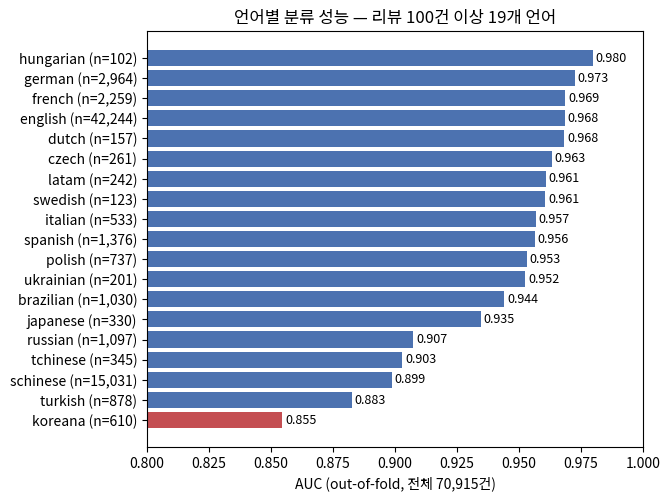

In [8]:
plot_df = lang_perf.sort_values('AUC')
labels = []
colors = []
for lang, n in zip(plot_df.index, plot_df['n']):
    labels.append(f'{lang} (n={n:,})')
    colors.append(C_NEG if lang == 'koreana' else C_POS)

fig, ax = plt.subplots(figsize=(6.4, 5.4))
bars = ax.barh(labels, plot_df['AUC'], color=colors)
ax.bar_label(bars, fmt='%.3f', fontsize=9, padding=2)
ax.set_xlim(0.8, 1.0)     # 0부터 그리면 언어 간 차이가 안 보인다
ax.set_xlabel('AUC (out-of-fold, 전체 70,915건)')
ax.set_title(f'언어별 분류 성능 — 리뷰 100건 이상 {len(plot_df)}개 언어')
fig.savefig('out/05b_언어별_AUC.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. 버튼과 글이 어긋나는 리뷰

- **불일치 추천**: 추천 버튼을 눌렀는데 글은 부정(추천확률 < 0.3)
- **불일치 비추천**: 비추천 버튼인데 글은 긍정(추천확률 ≥ 0.7)

경계 0.3 / 0.7은 07·08 노트북과 같다.

In [9]:
mis_pos = df[(df['voted_up'] == True) & (df['추천확률'] < 0.3)]
mis_neg = df[(df['voted_up'] == False) & (df['추천확률'] >= 0.7)]
n_pos = (df['voted_up'] == True).sum()
n_neg = (df['voted_up'] == False).sum()
print('불일치 추천  ', len(mis_pos), '건 (추천 리뷰의', round(len(mis_pos) / n_pos * 100, 1), '%)')
print('불일치 비추천', len(mis_neg), '건 (비추천 리뷰의', round(len(mis_neg) / n_neg * 100, 1), '%)')

# 60~200자짜리 리뷰에서 3건씩 뽑아 읽어 본다
for name, group in [('불일치 추천', mis_pos), ('불일치 비추천', mis_neg)]:
    print()
    print('[', name, '예시 ]')
    sample = group[group['len'].between(60, 200)].sample(3, random_state=RANDOM_STATE)
    for text in sample['review']:
        print(' -', text[:120].replace('\n', ' '))

불일치 추천   1775 건 (추천 리뷰의 4.4 %)
불일치 비추천 2008 건 (비추천 리뷰의 6.6 %)

[ 불일치 추천 예시 ]
 - It's a Bethesda game for sure. Would rather have Elder Scrolls 6 but here we are. Looking at you Todd! Wait for mod supp
 - 中规中矩，不思进取，小垃圾建模精细但是只能用来卖钱和装饰基地，能薅头发和裙子，当作辐射5玩还行，无缘年度，但不至于褒姒。
 - Got the most important story moment ruined by bugged animations and Bethesda Moments™ 9/10 ♥♥♥♥♥♥♥ great

[ 불일치 비추천 예시 ]
 - Really fun if you think loading screens are a good replacement for proper exploration and are OK with being in a loading
 - Game's alright, but all the small annoyances that keep reoccurring add up.
 - I must say sometimes the loading screens are the screenshots you've taken in game. Thats pretty cool...
